MLP (matched) run 5/5: 100%|██████████| 10000/10000 [00:04<00:00, 2482.93it/s, loss=0.2452]


saved results\test6_ablations.png
saved results\test6_ablations.pdf


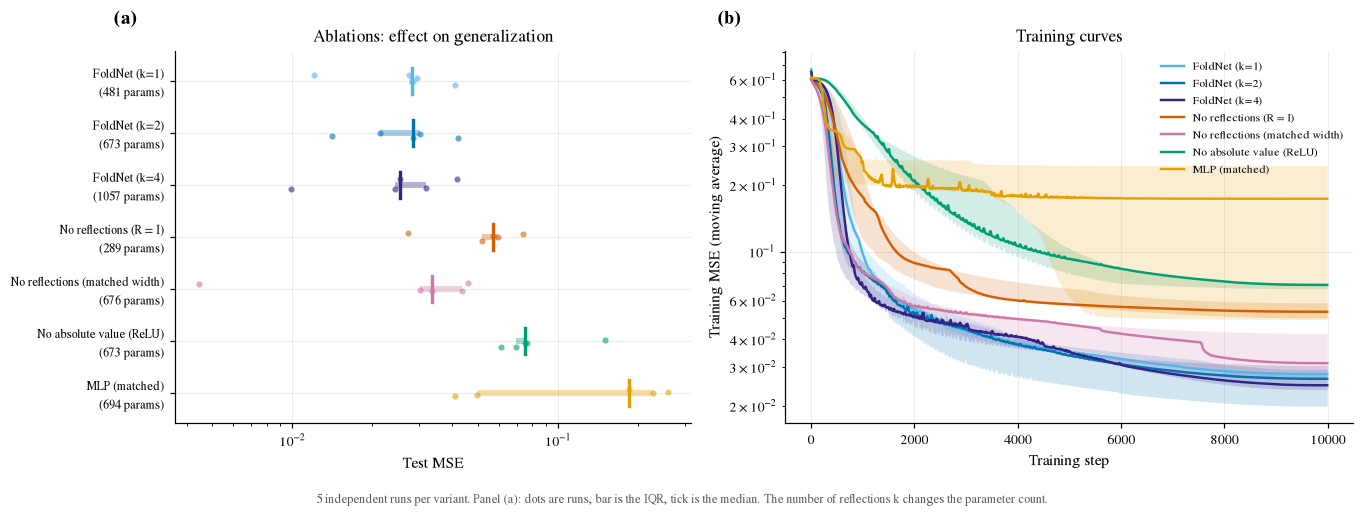

| Variant | Params | Test MSE | Factor vs FoldNet (k=2) | P(FoldNet (k=2) better) | p-value |
|---|---|---|---|---|---|
| FoldNet (k=1) | 481 | 2.82e-02 [2.75e-02, 2.95e-02] | x1.00 | 0.44 | n/a |
| FoldNet (k=2) | 673 | 2.84e-02 [2.13e-02, 3.02e-02] | x1.00 | - | - |
| FoldNet (k=4) | 1057 | **2.54e-02 [2.44e-02, 3.19e-02]** | x0.89 | 0.48 | n/a |
| No reflections (R = I) | 289 | 5.67e-02 [5.15e-02, 5.93e-02] | x2.00 | 0.88 | n/a |
| No reflections (matched width) | 676 | 3.35e-02 [3.01e-02, 4.37e-02] | x1.18 | 0.68 | n/a |
| No absolute value (ReLU) | 673 | 7.49e-02 [6.95e-02, 7.61e-02] | x2.64 | 1.00 | n/a |
| MLP (matched) | 694 | 1.85e-01 [4.95e-02, 2.28e-01] | x6.54 | 0.96 | n/a |
saved results\test6_ablations_table.{md,tex,csv}


In [1]:
"""Test 6: ablations (reflections, absolute value, number of reflections k), on TEST error."""
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from foldnet_lib import FoldNet, MLP, n_params
from foldnet_bench import benchmark, match_budget
import foldnet_viz as V

N_RUNS = 5
STEPS = 10000
D, DEPTH = 32, 6
REF = "FoldNet (k=2)"
RESULTS_DIR = "results"


class FoldNetNoRefl(nn.Module):
    """No reflections (R = I): coordinatewise |z - t|, no mixing between channels."""

    def __init__(self, din, dout, d=32, depth=6):
        super().__init__()
        self.inp = nn.Linear(din, d)
        self.t = nn.Parameter(0.5 * torch.randn(depth, d))
        self.out = nn.Linear(d, dout)

    def forward(self, x):
        x = self.inp(x)
        for l in range(self.t.shape[0]):
            x = (x - self.t[l]).abs()
        return self.out(x)


class FoldNetNoAbs(nn.Module):
    """Reflections kept, ReLU instead of the absolute value."""

    def __init__(self, din, dout, d=32, depth=6, k=2):
        super().__init__()
        self.inp = nn.Linear(din, d)
        self.v = nn.Parameter(torch.randn(depth, k, d))
        self.t = nn.Parameter(0.5 * torch.randn(depth, d))
        self.out = nn.Linear(d, dout)
        self.register_buffer("I", torch.eye(d))

    def forward(self, x):
        u = self.v / (self.v.pow(2).sum(-1, keepdim=True) + 1e-8).sqrt()
        M = self.I.expand(self.v.shape[0], -1, -1)
        for i in range(self.v.shape[1]):
            ui = u[:, i]
            M = M - 2 * ui.unsqueeze(-1) @ (ui.unsqueeze(1) @ M)
        Mt = M.transpose(1, 2)
        x = self.inp(x)
        for l in range(self.v.shape[0]):
            x = torch.relu(x @ Mt[l] - self.t[l])
        return self.out(x)


def f(x):
    return torch.sin(20 * x) + 0.5 * torch.sin(55 * x)


def smooth(a, k=25):
    return np.convolve(a, np.ones(k) / k, mode="valid")


TARGET = n_params(FoldNet(1, 1, D, DEPTH, 2))
VARIANTS = {
    "FoldNet (k=1)":                  lambda: FoldNet(1, 1, D, DEPTH, 1),
    "FoldNet (k=2)":                  lambda: FoldNet(1, 1, D, DEPTH, 2),
    "FoldNet (k=4)":                  lambda: FoldNet(1, 1, D, DEPTH, 4),
    "No reflections (R = I)":         lambda: FoldNetNoRefl(1, 1, D, DEPTH),
    "No reflections (matched width)": lambda: match_budget(lambda w: FoldNetNoRefl(1, 1, w, DEPTH), TARGET),
    "No absolute value (ReLU)":       lambda: FoldNetNoAbs(1, 1, D, DEPTH, 2),
    "MLP (matched)":                  lambda: match_budget(lambda w: MLP(1, 1, w, DEPTH), TARGET),
}
COLS = {
    "FoldNet (k=1)": "#56B4E9", "FoldNet (k=2)": "#0072B2", "FoldNet (k=4)": "#332288",
    "No reflections (R = I)": "#D55E00", "No reflections (matched width)": "#CC79A7",
    "No absolute value (ReLU)": "#009E73", "MLP (matched)": "#E69F00",
}

if __name__ == "__main__":
    V.set_style()
    names = list(VARIANTS)
    res, xs, ys = benchmark(VARIANTS, f, n_runs=N_RUNS, steps=STEPS)
    mse = {n: np.array([r["mse"] for r in res[n]]) for n in names}
    npar = {n: res[n][0]["n_params"] for n in names}

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), gridspec_kw=dict(width_ratios=[1, 1.1]))
    ax = axes[0]
    V.strip(ax, names, [mse[n] for n in names], COLS, horizontal=True)
    ax.set_yticklabels([f"{n}\n({npar[n]} params)" for n in names], fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel("Test MSE")
    ax.set_title("Ablations: effect on generalization")
    V.panel_label(ax, "(a)")

    ax = axes[1]
    for n in names:
        S = np.stack([smooth(r["curve"]) for r in res[n]])
        V.band(ax, np.arange(S.shape[1]) + 12, S, COLS[n], label=n)
    ax.set_yscale("log")
    ax.set_xlabel("Training step")
    ax.set_ylabel("Training MSE (moving average)")
    ax.set_title("Training curves")
    ax.legend(fontsize=7.5)
    V.panel_label(ax, "(b)")

    fig.text(0.5, -0.03, f"{N_RUNS} independent runs per variant. Panel (a): dots are runs, bar is "
             "the IQR, tick is the median. The number of reflections k changes the parameter count.",
             ha="center", fontsize=8, color="0.35")
    plt.tight_layout()
    V.savefig(fig, "test6_ablations", RESULTS_DIR)
    plt.show()

    tab = V.Table(["Variant", "Params", "Test MSE", f"Factor vs {REF}",
                   f"P({REF} better)", "p-value"])
    ref_med = float(np.median(mse[REF]))
    best = min(names, key=lambda n: np.median(mse[n]))
    for n in names:
        pb, pv = ("-", "-") if n == REF else V.vs_ref(mse[REF], mse[n])
        tab.add(n, npar[n], V.med_iqr(mse[n]), f"x{np.median(mse[n]) / ref_med:.2f}", pb, pv,
                bold={2} if n == best else ())
    tab.show()
    tab.save("test6_ablations_table", RESULTS_DIR,
             caption=(f"Ablations of FoldNet ({N_RUNS} runs), test MSE median [Q1, Q3]. "
                      "The factor is the ratio of medians to the reference variant. Bold: best median."),
             label="tab:ablations")